<a href="https://colab.research.google.com/github/lexie009/CBB6340/blob/main/CBB6340_A5_Data_exploration2_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install torch transformers scikit-learn matplotlib pandas requests tqdm

In [2]:
import json
import time
import html
import requests
import xml.etree.ElementTree as ET
import shelve
import numpy as np
import torch
import transformers

from transformers import AutoTokenizer, AutoModel
from datetime import datetime, timezone
from tqdm.auto import tqdm
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/pubmed_specter_2025")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

PAPERS_PATH = PROJECT_DIR / "papers_2025.json"
MANIFEST_PATH = PROJECT_DIR / "retrieval_manifest.json"
SHELF_PATH = PROJECT_DIR / "embeddings_2025"
PLOTS_DIR = PROJECT_DIR / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/pubmed_specter_2025


In [4]:
EMAIL = "lexuan.dai@yale.edu"
BASE_URL = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
SESSION = requests.Session()

TARGET_PER_GROUP = 1000
FETCH_BATCH_SIZE = 200

QUERIES = {
    "Alzheimer": (
        '("Alzheimer Disease"[MeSH Terms] OR alzheimer*[Title/Abstract]) '
        'AND 2025[Date - Publication]'
    ),
    "Cancer": (
        '("Neoplasms"[MeSH Terms] OR cancer[Title/Abstract] '
        'OR neoplasm*[Title/Abstract]) '
        'AND 2025[Date - Publication]'
    ),
}


def api_get(endpoint, params, max_attempts=5):
    """Request an E-utility endpoint with pacing and retries."""
    params = {
        **params,
        "tool": "pubmed_specter_portfolio",
        "email": EMAIL,
    }

    for attempt in range(max_attempts):
        time.sleep(0.4)

        try:
            response = SESSION.get(
                BASE_URL + endpoint,
                params=params,
                timeout=90,
            )
            response.raise_for_status()
            return response

        except requests.RequestException:
            if attempt == max_attempts - 1:
                raise

            time.sleep(2 ** (attempt + 1))

In [5]:
def clean_text(element):
    """Extract all text, including text inside nested XML tags."""
    if element is None:
        return ""

    text = "".join(element.itertext())
    return " ".join(html.unescape(text).split())


def search_pmids(query, number):
    """Retrieve a ranked list of PMIDs using ESearch."""
    response = api_get(
        "esearch.fcgi",
        {
            "db": "pubmed",
            "term": query,
            "retmode": "json",
            "retmax": number,
            "sort": "pub date",
        },
    )

    result = response.json()["esearchresult"]

    if "ERROR" in result or "errorlist" in result:
        raise RuntimeError(f"PubMed search error: {result}")

    return result["idlist"], {
        "total_matches": int(result["count"]),
        "query_translation": result.get("querytranslation", ""),
    }


def parse_article(article):
    """Convert one PubMed XML article into clean metadata."""
    citation = article.find("MedlineCitation")
    if citation is None:
        return None

    article_node = citation.find("Article")
    if article_node is None:
        return None

    pmid = clean_text(citation.find("PMID"))
    title = clean_text(article_node.find("ArticleTitle"))

    sections = []

    for section in article_node.findall("./Abstract/AbstractText"):
        text = clean_text(section)
        label = section.get("Label") or section.get("NlmCategory") or ""

        if text:
            sections.append({
                "label": label,
                "text": text,
            })

    abstract = " ".join(
        f"{section['label']}: {section['text']}"
        if section["label"]
        else section["text"]
        for section in sections
    )

    publication_date = clean_text(
        article_node.find("./Journal/JournalIssue/PubDate")
    )

    publication_types = [
        clean_text(node)
        for node in article_node.findall(
            "./PublicationTypeList/PublicationType"
        )
    ]

    doi = ""
    for node in article.findall("./PubmedData/ArticleIdList/ArticleId"):
        if node.get("IdType") == "doi":
            doi = clean_text(node)
            break

    if not pmid:
        return None

    return {
        "PMID": pmid,
        "ArticleTitle": title,
        "Abstract": abstract,
        "AbstractSections": sections,
        "Journal": clean_text(article_node.find("./Journal/Title")),
        "PublicationDate": publication_date,
        "PublicationTypes": publication_types,
        "DOI": doi,
    }


def fetch_metadata(pmids):
    """Fetch PubMed records in batches."""
    papers = {}

    for start in tqdm(
        range(0, len(pmids), FETCH_BATCH_SIZE),
        desc="Fetching metadata",
    ):
        batch = pmids[start:start + FETCH_BATCH_SIZE]

        response = api_get(
            "efetch.fcgi",
            {
                "db": "pubmed",
                "id": ",".join(batch),
                "retmode": "xml",
            },
        )

        root = ET.fromstring(response.content)

        if root.find(".//ERROR") is not None:
            raise RuntimeError(ET.tostring(root, encoding="unicode"))

        for article in root.findall("./PubmedArticle"):
            paper = parse_article(article)

            if paper is not None:
                papers[paper["PMID"]] = paper

    missing = set(pmids) - set(papers)

    if missing:
        raise RuntimeError(
            f"Metadata missing for {len(missing)} PMIDs. "
            "Rerun retrieval before continuing."
        )

    return papers

In [6]:
# Select 1,000 Alzheimer papers.
alzheimer_ids, alzheimer_info = search_pmids(
    QUERIES["Alzheimer"],
    TARGET_PER_GROUP,
)

alzheimer_ids = list(dict.fromkeys(alzheimer_ids))

if len(alzheimer_ids) != TARGET_PER_GROUP:
    raise RuntimeError("Could not retrieve 1,000 Alzheimer PMIDs.")

# Select 1,000 additional Cancer papers.
cancer_candidates, cancer_info = search_pmids(
    QUERIES["Cancer"],
    2 * TARGET_PER_GROUP,
)

alzheimer_set = set(alzheimer_ids)

cancer_ids = [
    pmid
    for pmid in dict.fromkeys(cancer_candidates)
    if pmid not in alzheimer_set
][:TARGET_PER_GROUP]

if len(cancer_ids) != TARGET_PER_GROUP:
    raise RuntimeError("Could not retrieve 1,000 distinct Cancer PMIDs.")

selected_ids = alzheimer_ids + cancer_ids

assert len(selected_ids) == 2000
assert len(set(selected_ids)) == 2000

metadata = fetch_metadata(selected_ids)

# Preserve the selected order in the JSON dictionary.
papers = {}

for group, ids in [
    ("Alzheimer", alzheimer_ids),
    ("Cancer", cancer_ids),
]:
    for pmid in ids:
        papers[pmid] = {
            **metadata[pmid],
            "Group": group,
        }

manifest = {
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "publication_year_filter": 2025,
    "queries": QUERIES,
    "sort": "pub date",
    "sampling": (
        "First 1,000 Alzheimer results, followed by first 1,000 "
        "Cancer results excluding already selected PMIDs."
    ),
    "search_results": {
        "Alzheimer": alzheimer_info,
        "Cancer": cancer_info,
    },
    "selected_pmids": {
        "Alzheimer": alzheimer_ids,
        "Cancer": cancer_ids,
    },
}

with open(PAPERS_PATH, "w", encoding="utf-8") as file:
    json.dump(papers, file, indent=2, ensure_ascii=False)

with open(MANIFEST_PATH, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

print("Saved papers:", len(papers))

for group in QUERIES:
    group_papers = [
        paper for paper in papers.values()
        if paper["Group"] == group
    ]

    missing_abstracts = sum(
        not paper["Abstract"] for paper in group_papers
    )

    print(
        f"{group}: {len(group_papers)} papers; "
        f"{missing_abstracts} missing abstracts"
    )

Fetching metadata:   0%|          | 0/10 [00:00<?, ?it/s]

Saved papers: 2000
Alzheimer: 1000 papers; 45 missing abstracts
Cancer: 1000 papers; 57 missing abstracts


In [7]:
MODEL_NAME = "allenai/specter"
MAX_LENGTH = 512

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)

model = model.to(device)
model.eval()

BATCH_SIZE = 16 if device.type == "cuda" else 4

print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Embedding dimension:", model.config.hidden_size)

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/222k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Device: cpu
Batch size: 4
Embedding dimension: 768


In [8]:
with open(PAPERS_PATH, encoding="utf-8") as file:
    papers = json.load(file)

with shelve.open(str(SHELF_PATH)) as embedding_db:
    pending_pmids = [
        pmid for pmid in papers
        if pmid not in embedding_db
    ]

    print("Already saved:", len(papers) - len(pending_pmids))
    print("Remaining:", len(pending_pmids))

    with torch.inference_mode():
        for start in tqdm(
            range(0, len(pending_pmids), BATCH_SIZE),
            desc="Generating embeddings",
        ):
            batch_pmids = pending_pmids[start:start + BATCH_SIZE]

            texts = [
                papers[pmid]["ArticleTitle"]
                + tokenizer.sep_token
                + papers[pmid]["Abstract"]
                for pmid in batch_pmids
            ]

            inputs = tokenizer(
                texts,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt",
            )

            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }

            outputs = model(**inputs)

            vectors = (
                outputs.last_hidden_state[:, 0, :]
                .cpu()
                .numpy()
                .astype(np.float32)
            )

            for pmid, vector in zip(batch_pmids, vectors):
                if vector.shape != (768,) or not np.isfinite(vector).all():
                    raise ValueError(f"Invalid embedding for PMID {pmid}")

                embedding_db[pmid] = vector

            embedding_db.sync()

print("Embedding generation complete.")

Already saved: 1998
Remaining: 2


Generating embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding generation complete.


In [12]:
embedding_config = {
    "model": MODEL_NAME,
    "model_commit": getattr(model.config, "_commit_hash", None),
    "max_length": MAX_LENGTH,
    "pooling": "last_hidden_state[:, 0, :]",
    "embedding_dimension": model.config.hidden_size,
    "dtype": "float32",
    "device": str(device),
    "batch_size": BATCH_SIZE,
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
}

with open(
    PROJECT_DIR / "embedding_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(embedding_config, file, indent=2)

print(embedding_config)

{'model': 'allenai/specter', 'model_commit': None, 'max_length': 512, 'pooling': 'last_hidden_state[:, 0, :]', 'embedding_dimension': 768, 'dtype': 'float32', 'device': 'cpu', 'batch_size': 4, 'torch_version': '2.11.0+cpu', 'transformers_version': '5.18.0'}


In [14]:
with open(PAPERS_PATH, encoding="utf-8") as file:
    papers = json.load(file)

pmids = list(papers.keys())

with shelve.open(str(SHELF_PATH), flag="r") as embedding_db:
    missing = [
        pmid for pmid in pmids
        if pmid not in embedding_db
    ]

    if missing:
        raise RuntimeError(
            f"{len(missing)} embeddings are missing. "
            "Run the embedding cell again."
        )

    X = np.stack([
        np.asarray(embedding_db[pmid], dtype=np.float32)
        for pmid in pmids
    ])

assert X.shape == (2000, 768)
assert np.isfinite(X).all()

print("Embedding matrix shape:", X.shape)

Embedding matrix shape: (2000, 768)


In [13]:
pca = PCA(n_components=3, svd_solver="full")
coordinates = pca.fit_transform(X)

pca_df = pd.DataFrame({
    "PMID": pmids,
    "Group": [papers[pmid]["Group"] for pmid in pmids],
    "Title": [papers[pmid]["ArticleTitle"] for pmid in pmids],
    "PC0": coordinates[:, 0],
    "PC1": coordinates[:, 1],
    "PC2": coordinates[:, 2],
})

pca_df.to_csv(
    PROJECT_DIR / "pca_coordinates.csv",
    index=False,
)

variance_df = pd.DataFrame({
    "Component": ["PC0", "PC1", "PC2"],
    "ExplainedVarianceRatio": pca.explained_variance_ratio_,
})

variance_df.to_csv(
    PROJECT_DIR / "pca_explained_variance.csv",
    index=False,
)

display(variance_df)

print(
    "Total variance explained by three components:",
    f"{pca.explained_variance_ratio_.sum():.2%}",
)

,Component,ExplainedVarianceRatio
0,PC0,0.175329
1,PC1,0.073081
2,PC2,0.046816


Total variance explained by three components: 29.52%


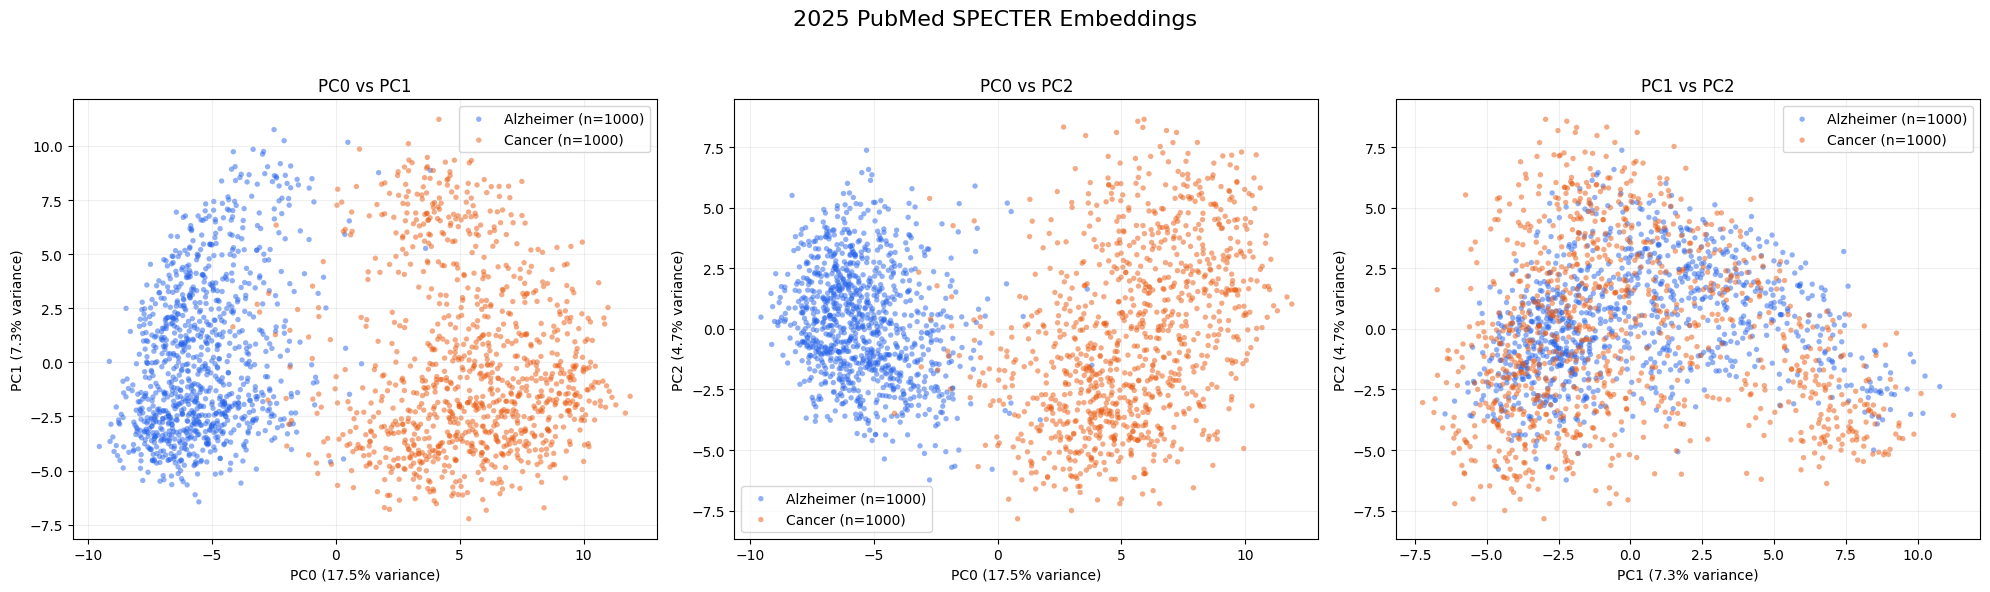

In [15]:
COLORS = {
    "Alzheimer": "#2563EB",
    "Cancer": "#EA580C",
}

component_index = {
    "PC0": 0,
    "PC1": 1,
    "PC2": 2,
}

pairs = [
    ("PC0", "PC1"),
    ("PC0", "PC2"),
    ("PC1", "PC2"),
]

# Create three subplots in one row.
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (x_component, y_component) in zip(axes, pairs):
    for group, color in COLORS.items():
        subset = pca_df[pca_df["Group"] == group]

        ax.scatter(
            subset[x_component],
            subset[y_component],
            label=f"{group} (n={len(subset)})",
            color=color,
            alpha=0.5,
            s=15,
            edgecolors="none",
        )

    x_variance = pca.explained_variance_ratio_[
        component_index[x_component]
    ]
    y_variance = pca.explained_variance_ratio_[
        component_index[y_component]
    ]

    ax.set_xlabel(f"{x_component} ({x_variance:.1%} variance)")
    ax.set_ylabel(f"{y_component} ({y_variance:.1%} variance)")
    ax.set_title(f"{x_component} vs {y_component}")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle("2025 PubMed SPECTER Embeddings", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])

# Save the combined figure.
output_path = PLOTS_DIR / "PCA_three_plots.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

In [16]:
pc_columns = ["PC0", "PC1", "PC2"]

centroids = pca_df.groupby("Group")[pc_columns].mean()

inspection_df = pca_df.copy()
distances = []

for _, row in inspection_df.iterrows():
    other_group = (
        "Cancer" if row["Group"] == "Alzheimer" else "Alzheimer"
    )

    point = row[pc_columns].to_numpy(dtype=float)
    other_centroid = centroids.loc[other_group].to_numpy(dtype=float)

    distances.append(np.linalg.norm(point - other_centroid))

inspection_df["DistanceToOtherCentroid"] = distances

for group in COLORS:
    print(f"\n{group} papers closest to the other group's centroid:")

    display(
        inspection_df[inspection_df["Group"] == group]
        .nsmallest(5, "DistanceToOtherCentroid")
        [["PMID", "Title", "DistanceToOtherCentroid"]]
    )

inspection_df.to_csv(
    PROJECT_DIR / "paper_inspection.csv",
    index=False,
)


Alzheimer papers closest to the other group's centroid:


,PMID,Title,DistanceToOtherCentroid
703,41459931,Systematic evaluation and optimization of TaqM...,4.420407
858,41341074,"Hospital mortality, withdrawal of life-sustain...",6.015837
334,40410107,Effect of Incidence Sites on Light Distributio...,6.291779
709,41187837,Ziziphi Spinosae Semen: A comprehensive review...,6.510710
458,41202177,Comparative analysis of plasma p-tau217 immuno...,6.521594



Cancer papers closest to the other group's centroid:


,PMID,Title,DistanceToOtherCentroid
1814,41325013,Etiologies of Acute Ataxia in Children: A Syst...,3.486998
1908,41175312,Gut microbiome signatures predict cognitive im...,3.659362
1787,41359511,Genetic Etiology of Infantile Spasms in Peruvi...,3.696670
1913,41160314,Elevated alpha-1 antitrypsin and C-reactive pr...,3.767421
1574,40762885,Visuospatial and Visuomotor Abilities of Indiv...,3.940492
